ABTest

In [4]:
import numpy as np
import pandas as pd
import seaborn as sns

In [5]:
a = np.array([23 , 21, 19, 24, 35, 17, 18, 24, 33, 27, 21, 23])
b = np.array([31 , 28, 19, 24, 32, 27, 16, 41, 23, 32, 29, 33])

In [6]:
a.mean()

23.75

In [7]:
b.mean()

27.916666666666668

In [8]:
d = b.mean() - a.mean()
d

4.166666666666668

In [9]:
np.ones(len(b))

array([1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.])

In [10]:
np.append(np.zeros(len(a)) , np.ones(len(b)))

array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1.])

In [11]:
sales = np.array(
    [
       np.append(np.zeros(len(a)) , np.ones(len(b))),
       np.append(a,b) 
    ]
)

In [12]:
print(sales)

[[ 0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  1.  1.  1.  1.  1.  1.
   1.  1.  1.  1.  1.  1.]
 [23. 21. 19. 24. 35. 17. 18. 24. 33. 27. 21. 23. 31. 28. 19. 24. 32. 27.
  16. 41. 23. 32. 29. 33.]]


In [13]:
sales_t = sales.T
sales_t

array([[ 0., 23.],
       [ 0., 21.],
       [ 0., 19.],
       [ 0., 24.],
       [ 0., 35.],
       [ 0., 17.],
       [ 0., 18.],
       [ 0., 24.],
       [ 0., 33.],
       [ 0., 27.],
       [ 0., 21.],
       [ 0., 23.],
       [ 1., 31.],
       [ 1., 28.],
       [ 1., 19.],
       [ 1., 24.],
       [ 1., 32.],
       [ 1., 27.],
       [ 1., 16.],
       [ 1., 41.],
       [ 1., 23.],
       [ 1., 32.],
       [ 1., 29.],
       [ 1., 33.]])

In [14]:
np.random.shuffle(sales_t)

In [15]:
sales_t

array([[ 0., 21.],
       [ 0., 33.],
       [ 1., 41.],
       [ 1., 33.],
       [ 0., 17.],
       [ 0., 18.],
       [ 1., 27.],
       [ 1., 31.],
       [ 0., 35.],
       [ 1., 32.],
       [ 0., 24.],
       [ 0., 23.],
       [ 1., 32.],
       [ 1., 28.],
       [ 1., 23.],
       [ 0., 23.],
       [ 0., 24.],
       [ 0., 19.],
       [ 1., 16.],
       [ 1., 19.],
       [ 0., 21.],
       [ 1., 24.],
       [ 1., 29.],
       [ 0., 27.]])

In [16]:
experiment_label = np.random.randint(0 , 2, len(sales_t))
experiment_label

array([0, 0, 1, 0, 1, 0, 0, 1, 1, 0, 0, 1, 0, 1, 0, 0, 1, 1, 1, 1, 1, 0,
       0, 0])

In [17]:
experiment_data = np.array(
    [
        experiment_label,
        sales_t[: , 1]
    ]
)
print(experiment_data)

[[ 0.  0.  1.  0.  1.  0.  0.  1.  1.  0.  0.  1.  0.  1.  0.  0.  1.  1.
   1.  1.  1.  0.  0.  0.]
 [21. 33. 41. 33. 17. 18. 27. 31. 35. 32. 24. 23. 32. 28. 23. 23. 24. 19.
  16. 19. 21. 24. 29. 27.]]


In [18]:
experiment_data_t = experiment_data.T
experiment_data_t

array([[ 0., 21.],
       [ 0., 33.],
       [ 1., 41.],
       [ 0., 33.],
       [ 1., 17.],
       [ 0., 18.],
       [ 0., 27.],
       [ 1., 31.],
       [ 1., 35.],
       [ 0., 32.],
       [ 0., 24.],
       [ 1., 23.],
       [ 0., 32.],
       [ 1., 28.],
       [ 0., 23.],
       [ 0., 23.],
       [ 1., 24.],
       [ 1., 19.],
       [ 1., 16.],
       [ 1., 19.],
       [ 1., 21.],
       [ 0., 24.],
       [ 0., 29.],
       [ 0., 27.]])

In [19]:
experiment_data_t[experiment_data_t [ :, 0] == 1][ :, 1]

array([41., 17., 31., 35., 23., 28., 24., 19., 16., 19., 21.])

In [20]:
experiment_data_t[experiment_data_t [ :, 0] == 0][ :, 1].mean()

26.615384615384617

In [21]:
experiment_data_t[experiment_data_t [ :, 0] == 1][ :, 1].mean()

24.90909090909091

In [22]:
np.empty([10 , 1])

array([[nan],
       [ 0.],
       [ 0.],
       [ 0.],
       [ 0.],
       [ 0.],
       [ 0.],
       [ 0.],
       [ 0.],
       [ 0.]])

In [23]:
def sh_exp(N):
    experiment_diff_mean = np.empty([N, 1])
    for times in np.arange(N):
        experiment_label = np.random.randint(0, 2, len(sales_t))
        experiment_data = np.array([
            experiment_label,
            sales_t[:, 1]
        ]).T
        experiment_diff_mean[times] = experiment_data[experiment_data[:, 0] == 1][:, 1].mean() - experiment_data[experiment_data[:, 0] == 0][:, 1].mean()
    return experiment_diff_mean

In [24]:
e1 = sh_exp(1000)

In [25]:
e1

array([[  4.66666667],
       [ -3.48571429],
       [ -3.83216783],
       [ -0.84033613],
       [  2.45378151],
       [ -1.33333333],
       [  6.28571429],
       [ -0.88888889],
       [ -4.5       ],
       [  1.08571429],
       [ -4.34285714],
       [ -1.25714286],
       [ -0.08888889],
       [  1.65034965],
       [ -0.44444444],
       [ -0.03361345],
       [ -0.13986014],
       [ -4.72727273],
       [  5.6       ],
       [ -1.65034965],
       [  1.04201681],
       [  0.1958042 ],
       [ -2.37762238],
       [  3.19327731],
       [  0.28571429],
       [ -3.125     ],
       [ -3.3125    ],
       [  0.33333333],
       [  1.86666667],
       [  3.2       ],
       [  2.18487395],
       [ -0.26666667],
       [  1.53846154],
       [ -1.08571429],
       [  1.33333333],
       [  0.05714286],
       [  0.8       ],
       [  1.        ],
       [  3.4375    ],
       [ -3.14285714],
       [  0.125     ],
       [  0.57142857],
       [ -0.33333333],
       [ -0

In [26]:
len(e1[e1 >= d])

84

In [27]:
76 / 1000 * 100

7.6

In [30]:
#sns.displot(e1 , bins = 50)

ABTest2

In [32]:
import matplotlib.pyplot as plt
import random

In [34]:
df = pd.read_csv('ab_data.csv')
df.head()

,user_id,timestamp,group,landing_page,converted
0,851104,2017-01-21 22:11:48.556739,control,old_page,0
1,804228,2017-01-12 08:01:45.159739,control,old_page,0
2,661590,2017-01-11 16:55:06.154213,treatment,new_page,0
3,853541,2017-01-08 18:28:03.143765,treatment,new_page,0
4,864975,2017-01-21 01:52:26.210827,control,old_page,1


In [35]:
df.shape

(294478, 5)

In [36]:
df['converted'].mean()

0.11965919355605512

In [38]:
df.nunique()

user_id         290584
timestamp       294478
group                2
landing_page         2
converted            2
dtype: int64

In [39]:
df.query('group == "treatment" and landing_page != "new_page" ')

,user_id,timestamp,group,landing_page,converted
308,857184,2017-01-20 07:34:59.832626,treatment,old_page,0
327,686623,2017-01-09 14:26:40.734775,treatment,old_page,0
357,856078,2017-01-12 12:29:30.354835,treatment,old_page,0
685,666385,2017-01-23 08:11:54.823806,treatment,old_page,0
713,748761,2017-01-10 15:47:44.445196,treatment,old_page,0
...,...,...,...,...,...
293773,688144,2017-01-16 20:34:50.450528,treatment,old_page,1
293817,876037,2017-01-17 16:15:08.957152,treatment,old_page,1
293917,738357,2017-01-05 15:37:55.729133,treatment,old_page,0
294014,813406,2017-01-09 06:25:33.223301,treatment,old_page,0


In [40]:
df.query('group == "control" and landing_page != "old_page" ')

,user_id,timestamp,group,landing_page,converted
22,767017,2017-01-12 22:58:14.991443,control,new_page,0
240,733976,2017-01-11 15:11:16.407599,control,new_page,0
490,808613,2017-01-10 21:44:01.292755,control,new_page,0
846,637639,2017-01-11 23:09:52.682329,control,new_page,1
850,793580,2017-01-08 03:25:33.723712,control,new_page,1
...,...,...,...,...,...
293894,741581,2017-01-09 20:49:03.391764,control,new_page,0
293996,942612,2017-01-08 13:52:28.182648,control,new_page,0
294200,928506,2017-01-13 21:32:10.491309,control,new_page,0
294253,886135,2017-01-06 12:49:20.509403,control,new_page,0


In [42]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 294478 entries, 0 to 294477
Data columns (total 5 columns):
 #   Column        Non-Null Count   Dtype 
---  ------        --------------   ----- 
 0   user_id       294478 non-null  int64 
 1   timestamp     294478 non-null  object
 2   group         294478 non-null  object
 3   landing_page  294478 non-null  object
 4   converted     294478 non-null  int64 
dtypes: int64(2), object(3)
memory usage: 11.2+ MB


In [46]:
df2t = df.query('group == "treatment" and landing_page == "new_page" ')
df2c = df.query('group == "control" and landing_page == "old_page" ')

In [47]:
df2 = df2c.merge(df2t , how = 'outer')
df2.head()

,user_id,timestamp,group,landing_page,converted
0,851104,2017-01-21 22:11:48.556739,control,old_page,0
1,804228,2017-01-12 08:01:45.159739,control,old_page,0
2,864975,2017-01-21 01:52:26.210827,control,old_page,1
3,936923,2017-01-10 15:20:49.083499,control,old_page,0
4,719014,2017-01-17 01:48:29.539573,control,old_page,0


In [49]:
df2.shape

(290585, 5)

In [48]:
df2.describe()

,user_id,converted
count,290585.000000,290585.000000
mean,788004.825246,0.119597
std,91224.582639,0.324490
min,630000.000000,0.000000
25%,709035.000000,0.000000
50%,787995.000000,0.000000
75%,866956.000000,0.000000
max,945999.000000,1.000000


In [50]:
df.nunique()

user_id         290584
timestamp       294478
group                2
landing_page         2
converted            2
dtype: int64

In [53]:
sum(df2['user_id'].duplicated())

1

In [55]:
df2[df2['user_id'].duplicated(keep = 'first')]

,user_id,timestamp,group,landing_page,converted
146678,773192,2017-01-14 02:55:59.590927,treatment,new_page,0


In [56]:
df2 = df2[~df2.user_id.duplicated(keep = 'first')]

In [57]:
df2.nunique()

user_id         290584
timestamp       290584
group                2
landing_page         2
converted            2
dtype: int64

In [58]:
df2.converted.mean() * 100

11.959708724499627

In [59]:
df2_treatment = df.query('group == "treatment"')
df2_control = df.query('group == "control"')

In [60]:
df2_control['converted'].mean() * 100

12.039917935897611

In [61]:
df2_treatment['converted'].mean() * 100

11.891957956489856

In [63]:
df2['converted'].mean() 

0.11959708724499628

In [64]:
1 - df2['converted'].mean() 

0.8804029127550037

In [65]:
len(df2_treatment)

147276

In [66]:
new_page_converted = np.random.choice([1 , 0] , size = len(df2_treatment) , p = [df2['converted'].mean() , (1 - df2['converted'].mean())] ) 

In [67]:
new_page_converted

array([1, 0, 1, ..., 0, 0, 0])

(array([129599.,      0.,      0.,      0.,      0.,      0.,      0.,
             0.,      0.,  17677.]),
 array([0. , 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1. ]),
 <BarContainer object of 10 artists>)

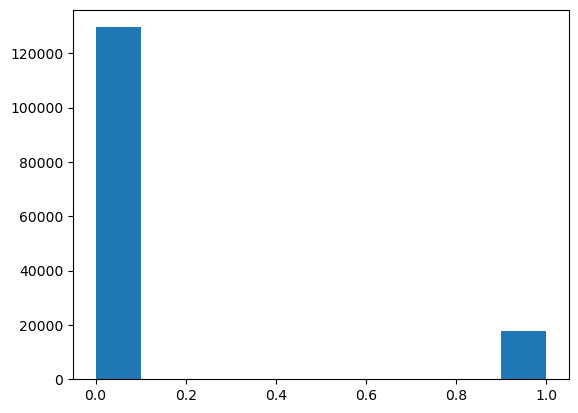

In [68]:
plt.hist(new_page_converted)

In [69]:
old_page_converted = np.random.choice([1 , 0] , size = len(df2_control) , p = [df2.converted.mean() , (1 - df2.converted.mean())] ) 

In [70]:
old_page_converted 

array([0, 0, 0, ..., 0, 1, 0])

(array([129607.,      0.,      0.,      0.,      0.,      0.,      0.,
             0.,      0.,  17595.]),
 array([0. , 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1. ]),
 <BarContainer object of 10 artists>)

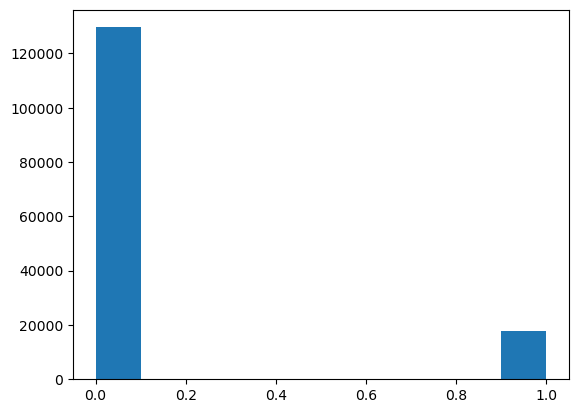

In [71]:
plt.hist(old_page_converted)

In [76]:
new_page_converted = np.random.binomial(len(df2_treatment), df2.converted.mean() , 10000) / len(df2_treatment)

In [78]:
old_page_converted = np.random.binomial(len(df2_control), df2.converted.mean() , 10000) / len(df2_control)

In [79]:
old_page_converted

array([0.11864649, 0.12015462, 0.11913561, ..., 0.12001875, 0.11895898,
       0.12011386])

In [80]:
p_diffs = new_page_converted - old_page_converted

In [81]:
p_diffs.mean()

9.832067499082902e-06

In [82]:
p_diffs

array([ 0.00063858,  0.00010869,  0.00114129, ..., -0.0005163 ,
        0.00032608, -0.00035326])

In [84]:
ab_data_diff = df2_treatment['converted'].mean() - df2_control['converted'].mean()
ab_data_diff

-0.0014795997940775518

In [85]:
(p_diffs > ab_data_diff).mean() * 100

89.41

In [86]:
(p_diffs < ab_data_diff).mean() * 100

10.59

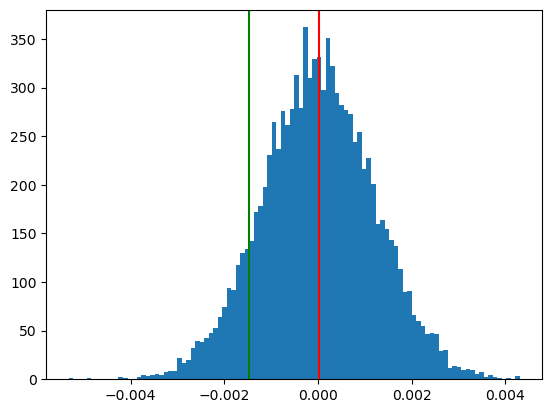

In [87]:
plt.hist(p_diffs, bins=100)
low = ab_data_diff
higth = p_diffs.mean()
plt.axvline(x=low, color='g')
plt.axvline(x=higth, color='r')